In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [67]:
from Bio import Phylo
import networkx as nx

tree = Phylo.read("../data/laml/problin_1461.nwk", "newick")

G = Phylo.to_networkx(tree)

print(G.number_of_nodes())
print(G.number_of_edges())

2921
2920


[autoreload of dataprocessor failed: Traceback (most recent call last):
  File "/Users/samin/workspace/phylodynamic-carta/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/samin/workspace/phylodynamic-carta/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
  File "/opt/homebrew/Cellar/python@3.13/3.13.15/Frameworks/Python.framework/Versions/3.13/lib/python3.13/importlib/__init__.py", line 129, in reload
    _bootstrap._exec(spec, module)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 1023, in exec_module
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/Users/samin/workspace/phylodynamic-carta/notebooks/../src/dataprocessor.py", line 11

In [70]:
from collections import defaultdict
from pathlib import Path

import convexml
import pandas as pd

problin_tree_path = Path("../data/laml/problin_1461.nwk")
allele_table_path = Path("../data/KPTracer-Data/KPTracer.alleleTable.FINAL.txt")
convexml_output_path = Path("../data/laml/problin_1461_convexml_timed.nwk")

problin_tree_newick = problin_tree_path.read_text().strip()
problin_tree = Phylo.read(str(problin_tree_path), "newick")
problin_leaf_names = [leaf.name for leaf in problin_tree.get_terminals()]

allele_table = pd.read_csv(
    allele_table_path,
    sep="\t",
    usecols=["cellBC", "intBC", "r1", "r2", "r3"],
    dtype=str,
)
allele_table = allele_table[allele_table["cellBC"].isin(problin_leaf_names)]
if allele_table.duplicated(["cellBC", "intBC"]).any():
    raise ValueError("Expected at most one allele-table row per cell and intBC")

cut_sites = ["r1", "r2", "r3"]
features = sorted(
    {
        (row.intBC, cut_site)
        for row in allele_table.itertuples(index=False)
        for cut_site in cut_sites
    }
)
feature_indices = {feature: index for index, feature in enumerate(features)}
alleles_by_feature = defaultdict(set)
for row in allele_table.itertuples(index=False):
    for cut_site in cut_sites:
        allele = getattr(row, cut_site)
        if pd.notna(allele):
            alleles_by_feature[(row.intBC, cut_site)].add(allele)

state_codes = {}
for feature in features:
    feature_alleles = alleles_by_feature[feature]
    unedited_alleles = sorted(
        allele for allele in feature_alleles if "[None]" in allele
    )
    edited_alleles = sorted(
        allele for allele in feature_alleles if "[None]" not in allele
    )
    state_codes[feature] = {allele: 0 for allele in unedited_alleles}
    state_codes[feature].update(
        {allele: state for state, allele in enumerate(edited_alleles, start=1)}
    )

leaf_sequences = {
    leaf_name: [-1] * len(features) for leaf_name in problin_leaf_names
}
for row in allele_table.itertuples(index=False):
    for cut_site in cut_sites:
        allele = getattr(row, cut_site)
        if pd.notna(allele):
            feature = (row.intBC, cut_site)
            leaf_sequences[row.cellBC][feature_indices[feature]] = state_codes[feature][allele]

sequence_lengths = {len(sequence) for sequence in leaf_sequences.values()}
if len(sequence_lengths) != 1 or set(leaf_sequences) != set(problin_leaf_names):
    raise ValueError("ConvexML sequences do not match the Problin tree leaves")

minimum_branch_length = min(0.01, 0.5 / (2 * len(problin_leaf_names) - 2))
print(
    f"Prepared {len(leaf_sequences)} leaves with {len(features)} allele features; "
    f"{len(problin_leaf_names) - allele_table['cellBC'].nunique()} leaves have no allele records."
)
print("Using minimum branch length", minimum_branch_length)

convexml_result = convexml.convexml(
    tree_newick=problin_tree_newick,
    leaf_sequences=leaf_sequences,
    ancestral_state_reconstructor="conservative_maximum_parsimony",
    resolve_multifurcations_before_branch_length_estimation=True,
    recover_multifurcations_after_branch_length_estimation=False,
    minimum_branch_length=minimum_branch_length,
    pseudo_mutations_per_edge=0.05,
    pseudo_non_mutations_per_edge=0.05,
    solver="ECOS",
    backup_solver="SCS",
    verbose=True,
)

convexml_output_path.write_text(convexml_result["tree_newick"] + "\n")
print("Saved ConvexML timed tree to", convexml_output_path)


Prepared 1461 leaves with 30 allele features; 10 leaves have no allele records.
Using minimum branch length 0.00017123287671232877


(CVXPY) Oct 07 03:05:14 AM: Your problem has 2922 variables, 4382 constraints, and 0 parameters.
(CVXPY) Oct 07 03:05:14 AM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 07 03:05:14 AM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 07 03:05:14 AM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 07 03:05:14 AM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 07 03:05:14 AM: Compiling problem (target solver=ECOS).
(CVXPY) Oct 07 03:05:14 AM: Reduction chain: FlipObjective -> Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> ECOS
(CVXPY) Oct 07 03:05:14 AM: Applying reduction FlipObjective
(CVXPY) Oct 07 03:05:14 AM: Applying reduction Dcp2Cone
(CVXPY) Oct 07 03:05:14 AM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 07 03:05:14 AM: Applying reduction ConeMatrixStuffing
(CVXPY) Oct 07 03:05:14 AM: Applyin

                                     CVXPY                                     
                                     v1.8.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------

ECOS 2.0.10 - (C) embotech GmbH, Zurich Switzerland, 2012-15. Web: www.embotech.com/ECOS

It     pcost       dcost      gap   pres   dres    k/t    mu     step   sigma     IR    |   BT
 0  +0.000e+00  -3.628e+03  +2e+04  7e-01  6e-01  1e+00  1e+00    ---    ---    0  0  - |  -  - 
 1  +1.677e+02  -2.329e+03  +1e+04  3e-01  5e-01  7e-01  7e-01  0.4628  3e-01

(CVXPY) Oct 07 03:05:14 AM: Problem status: optimal
(CVXPY) Oct 07 03:05:14 AM: Optimal value: -1.552e+02
(CVXPY) Oct 07 03:05:14 AM: Compilation took 2.185e-02 seconds
(CVXPY) Oct 07 03:05:14 AM: Solver (including time spent in interface) took 1.808e-01 seconds


35  +1.552e+02  +1.552e+02  +9e-07  7e-12  3e-11  2e-11  4e-11  0.6266  1e-01   0  0  0 |  3  2

OPTIMAL (within feastol=2.8e-11, reltol=5.5e-09, abstol=8.6e-07).
Runtime: 0.180230 seconds.

-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
Saved ConvexML timed tree to ../data/laml/problin_1461_convexml_timed.nwk


In [4]:
print(G.edges(data=True))
print(G.nodes(data=True))

[(Clade(branch_length=0.005), Clade(branch_length=0.19311067051961742), {'weight': 0.19311067051961742}), (Clade(branch_length=0.005), Clade(branch_length=0.005), {'weight': 0.005}), (Clade(branch_length=0.19311067051961742), Clade(branch_length=0.46475513319561146), {'weight': 0.46475513319561146}), (Clade(branch_length=0.19311067051961742), Clade(branch_length=2.282915814433405, name='L8.CGGAGCTTCGGAAATA-1'), {'weight': 2.282915814433405}), (Clade(branch_length=0.46475513319561146), Clade(branch_length=0.3843457381117571), {'weight': 0.3843457381117571}), (Clade(branch_length=0.46475513319561146), Clade(branch_length=1.818160681237794, name='L9.CTGCGGAGTAGGCTGA-1'), {'weight': 1.818160681237794}), (Clade(branch_length=0.3843457381117571), Clade(branch_length=1.4338149431260367, name='L9.GAACATCTCTCTAGGA-1'), {'weight': 1.4338149431260367}), (Clade(branch_length=0.3843457381117571), Clade(branch_length=0.912487875305582), {'weight': 0.912487875305582}), (Clade(branch_length=0.91248787

In [5]:
G.nodes

NodeView((Clade(branch_length=0.005), Clade(branch_length=0.19311067051961742), Clade(branch_length=0.46475513319561146), Clade(branch_length=0.3843457381117571), Clade(branch_length=1.4338149431260367, name='L9.GAACATCTCTCTAGGA-1'), Clade(branch_length=0.912487875305582), Clade(branch_length=0.0050035271521436), Clade(branch_length=0.005000661274110419), Clade(branch_length=0.5113228749087244, name='L11.CGAGCACGTACCGAGA-1'), Clade(branch_length=0.5113228749087244, name='L8.CAAGAAAGTCGCGGTT-1'), Clade(branch_length=0.5163235361828349, name='L8.GTCAAGTGTTCCACAA-1'), Clade(branch_length=0.5213270633349785, name='L11.TAGTGGTTCATACGGT-1'), Clade(branch_length=1.818160681237794, name='L9.CTGCGGAGTAGGCTGA-1'), Clade(branch_length=2.282915814433405, name='L8.CGGAGCTTCGGAAATA-1'), Clade(branch_length=0.005), Clade(branch_length=0.7878975489609431), Clade(branch_length=0.5970955952415664), Clade(branch_length=1.0860340747123287, name='L8.TCGAGGCGTATAAACG-1'), Clade(branch_length=1.0860340747123

In [6]:
for u, v, d in G.edges(data=True):
    print(u, v, d)

Clade Clade {'weight': 0.19311067051961742}
Clade Clade {'weight': 0.005}
Clade Clade {'weight': 0.46475513319561146}
Clade L8.CGGAGCTTCGGAAATA-1 {'weight': 2.282915814433405}
Clade Clade {'weight': 0.3843457381117571}
Clade L9.CTGCGGAGTAGGCTGA-1 {'weight': 1.818160681237794}
Clade L9.GAACATCTCTCTAGGA-1 {'weight': 1.4338149431260367}
Clade Clade {'weight': 0.912487875305582}
Clade Clade {'weight': 0.0050035271521436}
Clade L11.TAGTGGTTCATACGGT-1 {'weight': 0.5213270633349785}
Clade Clade {'weight': 0.005000661274110419}
Clade L8.GTCAAGTGTTCCACAA-1 {'weight': 0.5163235361828349}
Clade L11.CGAGCACGTACCGAGA-1 {'weight': 0.5113228749087244}
Clade L8.CAAGAAAGTCGCGGTT-1 {'weight': 0.5113228749087244}
Clade Clade {'weight': 0.7878975489609431}
Clade Clade {'weight': 0.005}
Clade Clade {'weight': 0.5970955952415664}
Clade L8.TCACGAATCCCATTAT-1 {'weight': 1.6831296699538951}
Clade L8.TCGAGGCGTATAAACG-1 {'weight': 1.0860340747123287}
Clade L8.GCTCCTAGTTCGTGAT-1 {'weight': 1.0860340747123287}
Cla

In [7]:
for n, d in G.nodes(data=True):
    print(n, d)

Clade {}
Clade {}
Clade {}
Clade {}
L9.GAACATCTCTCTAGGA-1 {}
Clade {}
Clade {}
Clade {}
L11.CGAGCACGTACCGAGA-1 {}
L8.CAAGAAAGTCGCGGTT-1 {}
L8.GTCAAGTGTTCCACAA-1 {}
L11.TAGTGGTTCATACGGT-1 {}
L9.CTGCGGAGTAGGCTGA-1 {}
L8.CGGAGCTTCGGAAATA-1 {}
Clade {}
Clade {}
Clade {}
L8.TCGAGGCGTATAAACG-1 {}
L8.GCTCCTAGTTCGTGAT-1 {}
L8.TCACGAATCCCATTAT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L9.GGGCACTAGTAACCCT-1 {}
L9.ACCTTTAGTCAAACTC-1 {}
L10.GTGCATAGTTATCCGA-1 {}
L8.CCGTACTCAGCTGCTG-1 {}
Clade {}
Clade {}
Clade {}
L9.TTTATGCTCCAGTATG-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L10.TGCCCATGTAGCGCTC-1 {}
Clade {}
L10.ATTGGTGGTTCGCTAA-1 {}
L10.CATCCACAGAAACGAG-1 {}
Clade {}
Clade {}
L10.TGATTTCGTCGCTTCT-1 {}
L10.GGGCACTTCTTACCTA-1 {}
L10.CACAGTAAGATGGCGT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L9.TCGTACCGTCAACATC-1 {}
L10.GAAATGACACGGCTAC-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L9.CAGCGACTCCTATTCA-1 {}
L10.TCGTAGAGTTGTTTGG-1 {}
L9.GGCTCGACAGCATGAG-1 

In [8]:
mapping = {
    node: i
    for i, node in enumerate(G.nodes())
}

G = nx.relabel_nodes(G, mapping)

In [9]:
for u, v in G.edges():
    G.edges[u, v]['length'] = G.edges[u, v]['weight']

In [10]:
root = tree.root

DG = nx.DiGraph()

for parent in tree.find_clades(order="level"):
    for child in parent.clades:
        DG.add_edge(parent, child, length=child.branch_length)

In [11]:
for n, d in DG.nodes(data=True):
    print(n, d)

Clade {}
Clade {}
Clade {}
Clade {}
L8.CGGAGCTTCGGAAATA-1 {}
Clade {}
Clade {}
Clade {}
L9.CTGCGGAGTAGGCTGA-1 {}
Clade {}
L8.TCACGAATCCCATTAT-1 {}
Clade {}
Clade {}
L9.GAACATCTCTCTAGGA-1 {}
Clade {}
L8.TCGAGGCGTATAAACG-1 {}
L8.GCTCCTAGTTCGTGAT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L11.TAGTGGTTCATACGGT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L8.GTCAAGTGTTCCACAA-1 {}
Clade {}
L8.CCGTACTCAGCTGCTG-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L8.TTCGGTCGTGATGTCT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
L11.CGAGCACGTACCGAGA-1 {}
L8.CAAGAAAGTCGCGGTT-1 {}
Clade {}
L10.GTGCATAGTTATCCGA-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
L10.TAGGCATTCAAACAAG-1 {}
L10.TGACGGCAGGGTGTGT-1 {}
Clade {}
Clade {}
L11.GGAACTTAGAGGGATA-1 {}
Clade {}
L11.ATGTGTGGTGTTCTTT-1 {}
L9.GGATGTTGTCTCATCC-1 {}
Clade {}
L11.CACACAAAGTTGAGAT-1 {}
L8.GACGTGCTCGAACGGA-1 {}
L9.ATTGGACAGACGCTTT-1 {}
Clade {}
Clade {}
Clade {}
L8.AGCTC

In [12]:
import numpy as np
import pandas as pd

In [13]:
df = pd.read_csv("../data/laml/KPTracer_meta.csv", index_col=0)
df

,TS_Present,RNA_Present,MULTI,TS_UMI,NUM_INTBC,Lane,Tumor,SubTumor,ES_clone,genotype,Mouse,Aging_Month,Batch_Library,Batch_Harvest,Aging_Time,MetFamily,lentiBC,is_normal,PercentUncut,annotated_normal_rna
L10.AAACCTGAGACGCAAC-1,True,True,ATCTCGGA,522.0,9.0,L10,3724_NT_T1,3724_NT_T1_14,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGAGTTGGC-1,True,True,ATCTCGGA,346.0,9.0,L10,3724_NT_T1,3724_NT_T1_14,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGCTCCTCT-1,True,True,GTCAATCG,349.0,9.0,L10,3724_NT_T1,3724_NT_T1_11,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGGCAGGTT-1,True,True,GCCCCGAA,512.0,9.0,L10,3724_NT_T1,3724_NT_T1_12,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGTACACCT-1,True,True,ATCTCGGA,274.0,9.0,L10,3724_NT_T1,3724_NT_T1_14,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
L33.TTGAACGTCCTCAATT-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,Negative,False,NaN,True
L33.TTGAACGTCTGCTGTC-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,GGGCATTAGTCCGCGT,False,NaN,True
L33.TTGGAACAGTGGTAGC-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,Negative,False,NaN,True
L33.TTGGCAAAGTATCGAA-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,NaN,False,NaN,True


In [14]:
df['Lane'].unique()

array(['L10', 'L11', 'L12', 'L13', 'L18', 'L19', 'L20', 'L21', 'L23',
       'L24', 'L25', 'L26', 'L27', 'L28', 'L30', 'L31', 'L32', 'L33',
       'L34', 'L35', 'L36', 'L37', 'L6', 'L7', 'L8', 'L9'], dtype=object)

In [15]:
for n in DG.nodes():
    node_name = str(n)

    if node_name in df.index:
        DG.nodes[n]["state"] = df.loc[node_name, "SubTumor"]

In [16]:
DG.nodes(data=True)

NodeDataView({Clade(branch_length=0.005): {}, Clade(branch_length=0.19311067051961742): {}, Clade(branch_length=0.005): {}, Clade(branch_length=0.46475513319561146): {}, Clade(branch_length=2.282915814433405, name='L8.CGGAGCTTCGGAAATA-1'): {'state': '3724_NT_T1_3'}, Clade(branch_length=0.7878975489609431): {}, Clade(branch_length=0.005): {}, Clade(branch_length=0.3843457381117571): {}, Clade(branch_length=1.818160681237794, name='L9.CTGCGGAGTAGGCTGA-1'): {'state': '3724_NT_T1_10'}, Clade(branch_length=0.5970955952415664): {}, Clade(branch_length=1.6831296699538951, name='L8.TCACGAATCCCATTAT-1'): {'state': '3724_NT_T1_3'}, Clade(branch_length=0.1260013610013078): {}, Clade(branch_length=0.005): {}, Clade(branch_length=1.4338149431260367, name='L9.GAACATCTCTCTAGGA-1'): {'state': '3724_NT_T1_10'}, Clade(branch_length=0.912487875305582): {}, Clade(branch_length=1.0860340747123287, name='L8.TCGAGGCGTATAAACG-1'): {'state': '3724_NT_T1_3'}, Clade(branch_length=1.0860340747123287, name='L8.GCT

In [17]:
state_dict = {
    'T1': 0,
    'L1': 1,
    'L2': 2,
    'L3': 3,
    'S1': 4,
}

In [18]:
from collections import defaultdict

state_count = defaultdict(int)

for n, d in DG.nodes(data=True):
    if 'state' in d:
        state_count[d['state'][8:10]] += 1

state_count


defaultdict(int, {'T1': 886, 'L1': 9, 'L3': 75, 'S1': 449, 'L2': 42})

In [19]:
mapping = {
    node: i + 1
    for i, node in enumerate(DG.nodes())
}

DG = nx.relabel_nodes(DG, mapping)

In [20]:
for n, d in DG.nodes(data=True):
    if 'state' in d:
        DG.nodes[n]['state'] = state_dict[d['state'][8:10]]

In [21]:
DG.add_edge(0, 1, length=1e-6)

In [22]:
with open("../data/KPTracer-Data/processed_data/1461.tree", "w") as f:
    for u, v, d in DG.edges(data=True):
        f.write(f"{u}\t{v}\n")

In [23]:
with open("../data/KPTracer-Data/processed_data/1461.labeling", "w") as f:
    for n, d in DG.nodes(data=True):
        if 'state' in d:
            state = d['state']
            f.write(f"{n}\t{state}\n")

In [24]:
from collections import defaultdict

state_count = defaultdict(int)

for n, d in DG.nodes(data=True):
    if 'state' in d:
        state_count[d['state']] += 1

state_count


defaultdict(int, {0: 886, 1: 9, 3: 75, 4: 449, 2: 42})

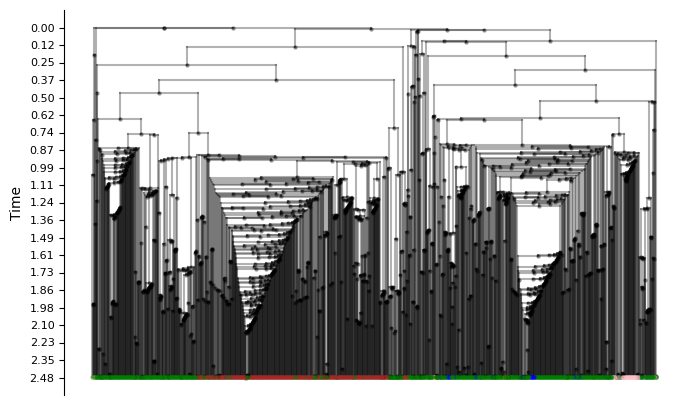

In [25]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(DG, root=0 , add_labels=False)

In [26]:
import networkx as nx

def enforce_min_edge_length(G, root, min_length):
    """
    Adjust node times so that every edge satisfies

        T[parent] - T[child] >= min_length

    Leaves are kept fixed.
    Internal nodes are moved upward only when necessary.

    Updates:
        node['T']
        edge['length']

    Parameters
    ----------
    G : nx.DiGraph
        Rooted tree with parent -> child edges.
    root : node
        Root node.
    min_length : float
        Minimum allowed edge length.

    Returns
    -------
    nx.DiGraph
        Modified copy of G.
    """

    H = G.copy()

    # Postorder = children before parent
    for u in nx.dfs_postorder_nodes(H, root):

        children = list(H.successors(u))

        # leaf: fixed
        if not children:
            continue

        required_time = max(
            H.nodes[v]["T"] + min_length
            for v in children
        )

        # move parent upward only if necessary
        if H.nodes[u]["T"] < required_time:
            H.nodes[u]["T"] = required_time

    # recompute edge lengths
    for u, v in H.edges():
        H.edges[u, v]["length"] = (
            H.nodes[u]["T"] - H.nodes[v]["T"]
        )

    return H

In [27]:
df = pd.read_csv("../data/laml/LL_dict.csv", index_col=0)
df

,v,state_0,state_1,state_2,state_3,state_4
u,,,,,,
8,14,-1.113965,-inf,-2.072276,-1.653954,-3.317805
32,50,-6.594526,-inf,-7.967722,-7.024863,-9.354879
32,51,-0.794907,-inf,-2.154489,-1.225245,-3.537688
22,32,-7.018509,-inf,-8.459194,-3.544582,-11.381203
22,33,-0.796176,-inf,-2.149502,-1.227273,-3.531170
...,...,...,...,...,...,...
13,21,498.415741,-inf,493.427128,504.538981,490.511463
7,13,489.836932,-inf,483.576873,495.976923,481.932535
3,7,812.739815,-inf,806.457904,818.880011,804.833852


In [28]:
state_cols = [c for c in df.columns if c.startswith("state_")]

df["best_state"] = df[state_cols].idxmax(axis=1)
df

,v,state_0,state_1,state_2,state_3,state_4,best_state
u,,,,,,,
8,14,-1.113965,-inf,-2.072276,-1.653954,-3.317805,state_0
32,50,-6.594526,-inf,-7.967722,-7.024863,-9.354879,state_0
32,51,-0.794907,-inf,-2.154489,-1.225245,-3.537688,state_0
22,32,-7.018509,-inf,-8.459194,-3.544582,-11.381203,state_3
22,33,-0.796176,-inf,-2.149502,-1.227273,-3.531170,state_0
...,...,...,...,...,...,...,...
13,21,498.415741,-inf,493.427128,504.538981,490.511463,state_3
7,13,489.836932,-inf,483.576873,495.976923,481.932535,state_3
3,7,812.739815,-inf,806.457904,818.880011,804.833852,state_3


In [29]:
for u, row in df.iterrows():
    best_state = row["best_state"]
    v = row["v"]
    print(u, v, int(best_state[6:]))

8 14 0
32 50 0
32 51 0
22 32 3
22 33 0
15 22 3
15 23 1
8 15 0
4 8 0
4 9 0
2 4 0
2 5 0
1 2 0
10 16 0
10 17 0
6 10 0
6 11 0
3 6 0
52 80 0
52 81 0
34 52 0
34 53 0
24 34 0
24 35 0
18 24 0
54 82 0
228 286 0
287 344 0
287 345 0
228 287 3
180 228 0
288 346 0
288 347 0
229 288 0
229 289 0
180 229 3
142 180 3
480 562 0
480 563 0
410 480 0
754 812 0
754 813 0
696 754 0
696 755 0
632 696 3
1020 1068 0
1252 1284 0
1252 1285 0
1188 1252 0
1430 1464 0
1550 1578 0
1698 1720 0
1854 1870 0
1886 1900 0
1886 1901 0
1871 1886 0
2080 2102 0
2080 2103 0
2062 2080 3
2062 2081 0
2048 2062 3
2048 2063 0
2028 2048 3
2028 2049 0
2010 2028 3
2010 2029 0
1992 2010 3
1992 2011 0
1980 1992 3
1980 1993 0
1972 1980 3
1972 1981 0
1962 1972 3
2168 2184 0
2168 2185 0
2156 2168 0
2186 2200 0
2201 2222 0
2223 2244 0
2223 2245 0
2201 2223 0
2186 2201 3
2169 2186 0
2312 2324 0
2312 2325 0
2298 2312 3
2298 2313 0
2286 2298 3
2286 2299 0
2274 2286 3
2274 2287 0
2262 2274 3
2262 2275 0
2246 2262 0
2246 2263 0
2224 2246 3
2224 2

In [30]:
DG.nodes(data=True)

NodeDataView({1: {}, 2: {}, 3: {}, 4: {}, 5: {'state': 0}, 6: {}, 7: {}, 8: {}, 9: {'state': 0}, 10: {}, 11: {'state': 0}, 12: {}, 13: {}, 14: {'state': 0}, 15: {}, 16: {'state': 0}, 17: {'state': 0}, 18: {}, 19: {}, 20: {}, 21: {}, 22: {}, 23: {'state': 1}, 24: {}, 25: {}, 26: {}, 27: {}, 28: {}, 29: {}, 30: {}, 31: {}, 32: {}, 33: {'state': 0}, 34: {}, 35: {'state': 0}, 36: {}, 37: {}, 38: {}, 39: {}, 40: {}, 41: {}, 42: {}, 43: {}, 44: {}, 45: {'state': 0}, 46: {}, 47: {}, 48: {}, 49: {}, 50: {'state': 3}, 51: {'state': 0}, 52: {}, 53: {'state': 0}, 54: {}, 55: {}, 56: {}, 57: {}, 58: {'state': 0}, 59: {'state': 0}, 60: {}, 61: {}, 62: {'state': 4}, 63: {}, 64: {'state': 4}, 65: {'state': 0}, 66: {}, 67: {'state': 4}, 68: {'state': 0}, 69: {'state': 0}, 70: {}, 71: {}, 72: {}, 73: {'state': 0}, 74: {'state': 0}, 75: {'state': 0}, 76: {}, 77: {}, 78: {}, 79: {'state': 0}, 80: {'state': 0}, 81: {'state': 0}, 82: {'state': 0}, 83: {}, 84: {}, 85: {}, 86: {}, 87: {}, 88: {}, 89: {'state

In [31]:
from likelihood import add_node_times

DG = add_node_times(DG, root=0)


In [32]:
leaves = [n for n, d in DG.out_degree() if d == 0]

distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

2.4760274804675464 2.476223176695044


In [33]:
for u, v, d in DG.edges(data=True):
    DG.edges[u, v]['length'] = DG.edges[u, v]['length'] / max_dist

In [34]:
leaves = [n for n, d in DG.out_degree() if d == 0]

distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999209698748724 0.9999999999999993


In [36]:
for leaf in leaves:
    distance = nx.shortest_path_length(DG, source=0, target=leaf, weight="length")
    if distance < 1.0:
        parent = next(DG.predecessors(leaf))
        edge_length = DG[parent][leaf]["length"]
        excess = 1.0 - distance
        DG[parent][leaf]["length"] = edge_length + excess

In [37]:
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

1.0 1.0


In [38]:
DG = add_node_times(DG, root=0)

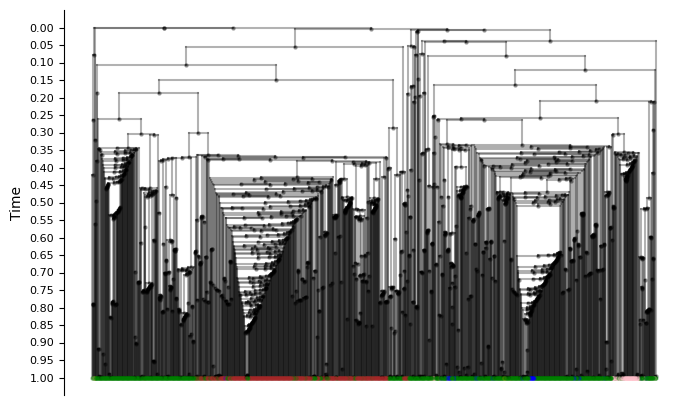

In [39]:
draw_ultrametric_tree(DG, root=0 , add_labels=False)

In [40]:
# DG = enforce_min_edge_length(DG, root=0, min_length=0.005)

In [41]:
# DG = add_node_times(DG, root=0)

In [42]:
# draw_ultrametric_tree(DG, root=0 , add_labels=False)

In [43]:
# leaves = [n for n, d in DG.out_degree() if d == 0]

# distances = {}
# for leaf in leaves:
#     distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

# min_dist = min(distances.values())
# max_dist = max(distances.values())
# print(min_dist, max_dist)

In [44]:
# for u, v, d in DG.edges(data=True):
#     DG.edges[u, v]['length'] = DG.edges[u, v]['length'] / (max_dist + 1e-6)

In [45]:
# leaves = [n for n, d in DG.out_degree() if d == 0]

# distances = {}
# for leaf in leaves:
#     distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

# min_dist = min(distances.values())
# max_dist = max(distances.values())
# print(min_dist, max_dist)

In [49]:
for n in DG.nodes():
    if n in leaves:
        DG.nodes[n]['is_leaf'] = True
    else:
        DG.nodes[n]['is_leaf'] = False

In [50]:
from dataprocessor import export_tree

export_tree(DG, f"../data/KPTracer-Data/processed_data/nodes_0.csv", f"../data/KPTracer-Data/processed_data/edges_0.csv")

In [51]:
df = pd.read_csv("../data/KPTracer-Data/processed_data/0-T-0.refined.tree", sep="\t", header=None)
df

,0,1,2
0,1,2,-1
1,1,3,-1
2,2,4,-1
3,2,5,-1
4,3,6,-1
...,...,...,...
2916,2916,2918,-1
2917,2916,2919,-1
2918,2918,2920,10
2919,2918,2921,-1


In [52]:
df_nodes = pd.read_csv("../data/KPTracer-Data/processed_data/nodes_0.csv")
df_nodes

,node_id,T,is_leaf,state_id
0,1,1.000000,0,-1
1,2,0.922014,0,-1
2,3,0.997980,0,-1
3,4,0.734327,0,-1
4,5,0.000000,1,0
...,...,...,...,...
2917,2918,0.002019,0,-1
2918,2919,0.000000,1,0
2919,2920,0.000000,1,4
2920,2921,0.000000,1,0


In [53]:
df_merged = pd.merge(df, df_nodes, left_on=0, right_on='node_id')
df_merged.rename(columns={'T': 'T_0'}, inplace=True)
df_merged = pd.merge(df_merged, df_nodes, left_on=1, right_on='node_id')
df_merged = df_merged.rename(columns={'T': 'T_1'})
df_merged

,0,1,2,node_id_x,T_0,is_leaf_x,state_id_x,node_id_y,T_1,is_leaf_y,state_id_y
0,1,2,-1,1,1.000000,0,-1,2,0.922014,0,-1
1,1,3,-1,1,1.000000,0,-1,3,0.997980,0,-1
2,2,4,-1,2,0.922014,0,-1,4,0.734327,0,-1
3,2,5,-1,2,0.922014,0,-1,5,0.000000,1,0
4,3,6,-1,3,0.997980,0,-1,6,0.679795,0,-1
...,...,...,...,...,...,...,...,...,...,...,...
2916,2916,2918,-1,2916,0.004038,0,-1,2918,0.002019,0,-1
2917,2916,2919,-1,2916,0.004038,0,-1,2919,0.000000,1,0
2918,2918,2920,10,2918,0.002019,0,-1,2920,0.000000,1,4
2919,2918,2921,-1,2918,0.002019,0,-1,2921,0.000000,1,0


In [54]:
df_filt = df_merged[df_merged[2] != -1]
df_filt

,0,1,2,node_id_x,T_0,is_leaf_x,state_id_x,node_id_y,T_1,is_leaf_y,state_id_y
21,15,23,6,15,0.210612,0,-1,23,0.000000,1,1
38,27,40,2,27,0.498083,0,-1,40,0.496063,0,-1
40,28,42,2,28,0.810083,0,-1,42,0.535407,0,-1
48,32,50,1,32,0.206572,0,-1,50,0.000000,1,3
62,41,64,2,41,0.417028,0,-1,64,0.000000,1,4
...,...,...,...,...,...,...,...,...,...,...,...
2684,2682,2686,0,2682,0.205644,0,-1,2686,0.203624,0,-1
2701,2698,2703,7,2698,0.002076,0,-1,2703,0.000000,1,0
2734,2732,2736,7,2732,0.181410,0,-1,2736,0.167085,0,-1
2911,2909,2913,9,2909,0.127633,0,-1,2913,0.008078,0,-1


In [55]:
df_location = pd.read_csv('../data/KPTracer-Data/processed_data/0-T-0.location.labeling', sep='\t', header=None)
df_location.rename(columns={0: 'node_id', 1: 'state'}, inplace=True)
df_location

,node_id,state
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0
...,...,...
2917,2918,0
2918,2919,0
2919,2920,4
2920,2921,0


In [56]:
df_merged = pd.merge(df_filt[[0, 1, 2, 'T_0', 'T_1']], df_location, left_on=0, right_on='node_id')
df_merged.rename(columns={'state': 'state_0'}, inplace=True)
df_merged = pd.merge(df_merged[[0, 1, 2, 'T_0', 'T_1', 'state_0']], df_location, left_on=1, right_on='node_id')
df_merged.rename(columns={'state': 'state_1'}, inplace=True)
df_merged

,0,1,2,T_0,T_1,state_0,node_id,state_1
0,15,23,6,0.210612,0.000000,0,23,1
1,27,40,2,0.498083,0.496063,0,40,4
2,28,42,2,0.810083,0.535407,0,42,4
3,32,50,1,0.206572,0.000000,0,50,3
4,41,64,2,0.417028,0.000000,0,64,4
...,...,...,...,...,...,...,...,...
94,2682,2686,0,0.205644,0.203624,0,2686,2
95,2698,2703,7,0.002076,0.000000,2,2703,0
96,2732,2736,7,0.181410,0.167085,2,2736,0
97,2909,2913,9,0.127633,0.008078,4,2913,0


In [57]:

transition_times_of_edges = []

for data in df_merged.itertuples():
    transition_times_of_edges.append(( data[0], data[1], data.state_0, data.state_1, (data.T_0 + data.T_1) / 2 ))

In [58]:
transition_times_of_edges

[(0, 15, 0, 1, 0.105306089626893),
 (1, 27, 0, 4, 0.49707319221613566),
 (2, 28, 0, 4, 0.672744789673127),
 (3, 32, 0, 3, 0.10328603979446915),
 (4, 41, 0, 4, 0.2085140674373862),
 (5, 55, 0, 4, 0.667582439122222),
 (6, 84, 0, 4, 0.4955107057344187),
 (7, 94, 4, 0, 0.24601138693835856),
 (8, 151, 4, 0, 0.1123442699760467),
 (9, 176, 0, 3, 0.3252325780956501),
 (10, 177, 0, 1, 0.27396029972039876),
 (11, 244, 4, 0, 0.00105095474908465),
 (12, 248, 4, 0, 0.0010507337978433),
 (13, 282, 0, 3, 0.6920106003599898),
 (14, 283, 0, 3, 0.34378881266592987),
 (15, 314, 4, 0, 0.0010501745754826),
 (16, 343, 0, 3, 0.39296868448097144),
 (17, 377, 4, 0, 0.11115418102141225),
 (18, 398, 0, 1, 0.1920877831666854),
 (19, 404, 0, 3, 0.5914630545881878),
 (20, 405, 0, 3, 0.6438155817970324),
 (21, 408, 0, 3, 0.3532947993559308),
 (22, 444, 4, 0, 0.12162633404881895),
 (23, 470, 0, 3, 0.1959250994047608),
 (24, 514, 4, 0, 0.16265890782828255),
 (25, 535, 0, 3, 0.19006763473377744),
 (26, 592, 4, 0, 0.001

In [59]:
node_colors = [(row.node_id, row.state) for row in df_location.itertuples()]
node_colors

[(1, 0),
 (2, 0),
 (3, 0),
 (4, 0),
 (5, 0),
 (6, 0),
 (7, 0),
 (8, 0),
 (9, 0),
 (10, 0),
 (11, 0),
 (12, 0),
 (13, 0),
 (14, 0),
 (15, 0),
 (16, 0),
 (17, 0),
 (18, 0),
 (19, 0),
 (20, 0),
 (21, 0),
 (22, 0),
 (23, 1),
 (24, 0),
 (25, 0),
 (26, 0),
 (27, 0),
 (28, 0),
 (29, 0),
 (30, 0),
 (31, 0),
 (32, 0),
 (33, 0),
 (34, 0),
 (35, 0),
 (36, 0),
 (37, 0),
 (38, 0),
 (39, 0),
 (40, 4),
 (41, 0),
 (42, 4),
 (43, 0),
 (44, 0),
 (45, 0),
 (46, 0),
 (47, 0),
 (48, 0),
 (49, 0),
 (50, 3),
 (51, 0),
 (52, 0),
 (53, 0),
 (54, 0),
 (55, 0),
 (56, 0),
 (57, 0),
 (58, 0),
 (59, 0),
 (60, 0),
 (61, 0),
 (62, 4),
 (63, 4),
 (64, 4),
 (65, 0),
 (66, 4),
 (67, 4),
 (68, 0),
 (69, 0),
 (70, 0),
 (71, 0),
 (72, 0),
 (73, 0),
 (74, 0),
 (75, 0),
 (76, 0),
 (77, 0),
 (78, 0),
 (79, 0),
 (80, 0),
 (81, 0),
 (82, 0),
 (83, 0),
 (84, 0),
 (85, 4),
 (86, 0),
 (87, 0),
 (88, 0),
 (89, 0),
 (90, 0),
 (91, 0),
 (92, 0),
 (93, 0),
 (94, 4),
 (95, 4),
 (96, 4),
 (97, 4),
 (98, 0),
 (99, 0),
 (100, 0),
 (101, 0

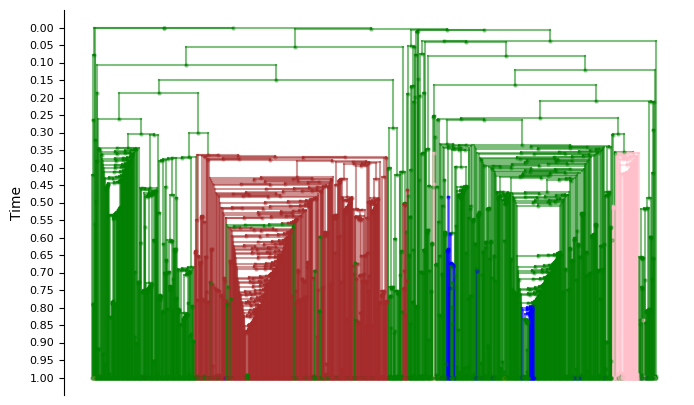

In [60]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(DG, root=0 , add_labels=False, node_colors=node_colors, transition_times_of_edges=transition_times_of_edges)

In [61]:
for n, c in node_colors:
    DG.nodes[n]['state'] = c

In [62]:
export_tree(DG, f"../data/KPTracer-Data/processed_data/nodes_0.csv", f"../data/KPTracer-Data/processed_data/edges_0.csv")

In [63]:
with open('../data/KPTracer-Data/processed_data/transitions_0.csv', 'w') as f:
    print("parent,child,s0,s1,t", file=f)
    for u, v, s0, s1, t in transition_times_of_edges:
        f.write(f"{u},{v},{s0},{s1},{t}\n")

In [64]:
transition_edges = df_merged[df_merged["state_0"] != df_merged["state_1"]].copy()
transition_edges["interval_start"] = transition_edges[["T_0", "T_1"]].min(axis=1)
transition_edges["interval_end"] = transition_edges[["T_0", "T_1"]].max(axis=1)

minimum_transition_times = []

for (state_0, state_1), state_edges in transition_edges.groupby(["state_0", "state_1"], sort=False):
    overlap_group = []
    shared_start = None
    shared_end = None

    for _, edge in state_edges.sort_values("interval_end").iterrows():
        if overlap_group:
            next_start = max(shared_start, edge.interval_start)
            next_end = min(shared_end, edge.interval_end)
        else:
            next_start = edge.interval_start
            next_end = edge.interval_end

        if overlap_group and next_start < next_end:
            overlap_group.append(edge)
            shared_start = next_start
            shared_end = next_end
        else:
            if overlap_group:
                minimum_transition_times.append(shared_start)

            overlap_group = [edge]
            shared_start = edge.interval_start
            shared_end = edge.interval_end

    if overlap_group:
        minimum_transition_times.append(shared_start)

minimum_transition_times

[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.4284953717393478),
 np.float64(0.4960629716934758),
 np.float64(0.6369944209813925),
 np.float64(0.1654961867984234),
 np.float64(0.6428059797451944),
 np.float64(0.0),
 np.float64(0.0080776798921717),
 np.float64(0.3032395046393126),
 np.float64(0.438591392257727),
 np.float64(0.0),
 np.float64(0.2036243301714878),
 np.float64(0.4105517696009744),
 np.float64(0.5163028032166411),
 np.float64(0.0),
 np.float64(0.0046930058783121),
 np.float64(0.0),
 np.float64(0.1670852696349529),
 np.float64(0.317901159547208),
 np.float64(0.0)]

In [65]:
sorted(minimum_transition_times)

[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0046930058783121),
 np.float64(0.0080776798921717),
 np.float64(0.1654961867984234),
 np.float64(0.1670852696349529),
 np.float64(0.2036243301714878),
 np.float64(0.3032395046393126),
 np.float64(0.317901159547208),
 np.float64(0.4105517696009744),
 np.float64(0.4284953717393478),
 np.float64(0.438591392257727),
 np.float64(0.4960629716934758),
 np.float64(0.5163028032166411),
 np.float64(0.6369944209813925),
 np.float64(0.6428059797451944)]

In [66]:
with open("../data/KPTracer-Data/processed_data/transition-times.txt", "w") as f:
    for time in sorted(minimum_transition_times):
        f.write(f"{time}\n")

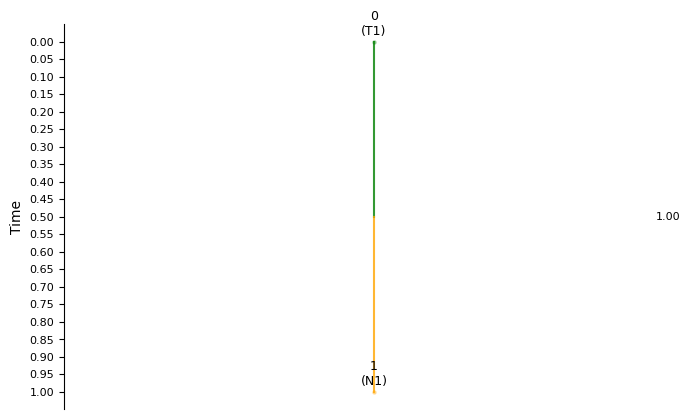

In [587]:
import networkx as nx
from plotters import draw_ultrametric_tree

example_tree = nx.DiGraph()
example_tree.add_node(0, T=1.0)
example_tree.add_node(1)
example_tree.add_edge(0, 1, length=1.0)

example_node_colors = [(0, "T1"), (1, "N1")]
example_transitions = [(0, 1, "T1", "N1", 0.5)]

draw_ultrametric_tree(
    example_tree,
    root=0,
    add_labels=True,
    node_colors=example_node_colors,
    transition_times_of_edges=example_transitions,
)